In [11]:
from matplotlib.animation import FuncAnimation, PillowWriter
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import json
import time

DATA_DIR = Path("../data/")
FIGURES_DIR = Path("../figures/")


In [12]:
with open(DATA_DIR / "inputs.json", "r") as f:
    inputs = json.load(f)

# Extract parameters
diffusivity = inputs["diffusivity_mm2_s"]  # [mm²/s]
length = inputs["length_mm"]               # [mm]
height = inputs["height_mm"]               # [mm]
space_step = inputs["space_step_mm"]       # [mm]
total_time = inputs["total_time_s"]        # [s]

initial_temperature = inputs["initial_temperature_C"]  # [°C]
boundary_temperature = inputs["boundary_temperature_C"]

In [13]:
x_nodes = int(length/space_step) + 1
y_nodes = int(height/space_step) + 1

time_step = 1/(4*diffusivity) * space_step**2
time_nodes = int(total_time/time_step) + 1

In [14]:
initial_temperature_dist = np.full((x_nodes, y_nodes), initial_temperature, dtype=float)

initial_temperature_dist[0, :]  = boundary_temperature["left"] # [°C] left edge boundary temperature of the plate
initial_temperature_dist[:, -1] = boundary_temperature["top"] # [°C] top //
initial_temperature_dist[-1, :] = boundary_temperature["right"] # [°C] right //
initial_temperature_dist[:, 0]  = boundary_temperature["bottom"] # [°C] bottom //


In [15]:
# simulation

start = time.perf_counter()

temperature_dist_collection = np.zeros((x_nodes, y_nodes, time_nodes))

average_temperature_collection = np.zeros(time_nodes)
center_temperature_collection = np.zeros(time_nodes)

temperature_dist = initial_temperature_dist.copy()

temperature_dist_collection[:, :, 0] = initial_temperature_dist
average_temperature_collection[0] = initial_temperature_dist.mean()
center_temperature_collection[0] = initial_temperature_dist[x_nodes // 2, y_nodes // 2]


difference_critereon = 0.1 # [°C] critereon to reach equilibrium
for t in np.arange(1, time_nodes):

    T = temperature_dist
    T_new = T.copy()

    # vectorizing the computation
    ddT_ddx_term = (T[2:, 1:-1] - 2*T[1:-1, 1:-1] + T[:-2, 1:-1]) / space_step**2
    ddT_ddy_term = (T[1:-1, 2:] - 2*T[1:-1, 1:-1] + T[1:-1, :-2]) / space_step**2

    T_new[1:-1, 1:-1] = T[1:-1, 1:-1] + time_step * diffusivity * (ddT_ddx_term + ddT_ddy_term)

    temperature_dist = T_new
    temperature_dist_collection[:, :, t] = temperature_dist

    average_temperature_collection[t] = temperature_dist.mean()
    center_temperature_collection[t]  = temperature_dist[x_nodes//2, y_nodes//2]


simulation_time = time.perf_counter() - start

print(f"simulation time: {simulation_time:.4f} s")  

simulation time: 0.2283 s


In [16]:
# visualization
fig, axis = plt.subplots()

animated_simulation = axis.imshow(
    temperature_dist.T,
    origin="lower",
    extent=[0, length, 0, height],
    aspect="equal",
    cmap="jet",
    vmin=np.min(list(boundary_temperature.values()) + [initial_temperature]),
    vmax=np.max(list(boundary_temperature.values()) + [initial_temperature]),
)

plt.colorbar(animated_simulation, ax=axis)
axis.set_title("simulation of the heat equation")
axis.set_xlabel(f"length of the plate in [mm]")
axis.set_ylabel(f"height of the plate in [mm]")

simulation_title = (
    f"simulation of the heat equation.\n" +
    f"time: {t}/{time_nodes-1} | average T: {average_temperature_collection[t]:.2f} °C."
)

axis.set_title(simulation_title)
plt.close(fig);

In [17]:
# animation

def update_data(
        frame, 
        axis, 
        animated_simulation, 
        temperature_dist_collection,
        average_temperature_collection
    ):

    animated_simulation.set_data(temperature_dist_collection[:, :, frame].T)
    simulation_title = (
        f"simulation of the heat equation.\n" +
        f"time: {frame}/{time_nodes} | average T: {average_temperature_collection[frame]:.2f} °C."
    )

    axis.set_title(simulation_title)
    return animated_simulation

animation = FuncAnimation(
    fig=fig,
    func=update_data,
    frames=np.arange(0, time_nodes, 5),
    fargs=(
        axis, 
        animated_simulation, 
        temperature_dist_collection, 
        average_temperature_collection
    ),
    interval=24,
    blit=True,
)


animation.save(
    "../assets/animation.gif",
    writer=PillowWriter(fps=24),
    dpi=70,
)

In [18]:
# exporting results
outputs = {
    "final_time_s": (time_nodes - 1) * time_step,
    "mean_temperature_C": float(temperature_dist.mean()),
    "center_temperature_C": float(temperature_dist[x_nodes // 2, y_nodes // 2]),
    "simulation_time_s": simulation_time
}

with open(DATA_DIR / "inputs.json", "w") as f:
    json.dump(inputs, f, indent=4)

with open(DATA_DIR / "outputs.json", "w") as f:
    json.dump(outputs, f, indent=4)

figure 1

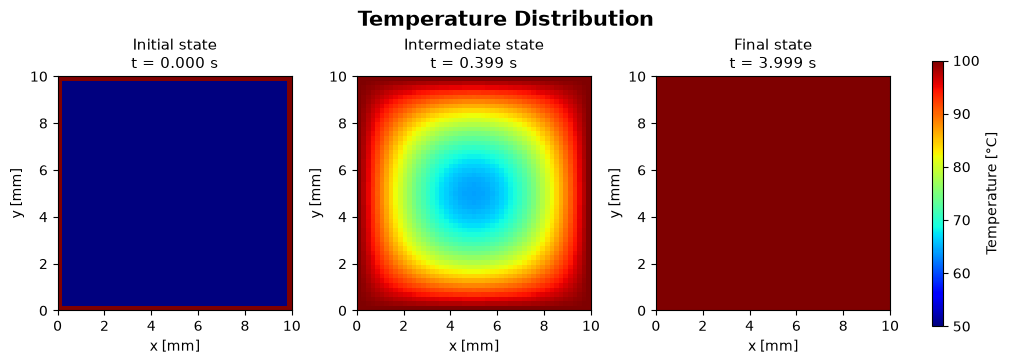

In [19]:
# Temperature distribution at three time points
fig, axes = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(10, 3.5),
    layout="constrained",
)

# Shared color scale
vmin = min(initial_temperature, *boundary_temperature.values())
vmax = max(initial_temperature, *boundary_temperature.values())

time_indices = [
    0,
    (time_nodes - 1) // 10,
    time_nodes - 1,
]

time_labels = [
    "Initial state",
    "Intermediate state",
    "Final state",
]

# Plot each temperature field
for ax, idx, label in zip(axes, time_indices, time_labels):
    temperature = temperature_dist_collection[:, :, idx].T

    im = ax.imshow(
        temperature,
        origin="lower",
        extent=[0, length, 0, height],
        aspect="equal",
        cmap="jet",
        vmin=vmin,
        vmax=vmax,
        interpolation="nearest",
    )

    ax.set_title(f"{label}\nt = {idx * time_step:.3f} s", fontsize=11)
    ax.set_xlabel("x [mm]")
    ax.set_ylabel("y [mm]")
    ax.set_box_aspect(height / length)

# Main title
fig.suptitle(
    "Temperature Distribution",
    fontsize=15,
    fontweight="bold",
)

# Shared colorbar
cbar = fig.colorbar(
    im,
    ax=axes,
    location="right",
    shrink=1.0,
    pad=0.04,
    aspect=25,
)
cbar.set_label("Temperature [°C]")

# Export
fig.savefig(
    FIGURES_DIR / "fig_temperature_distribution.png",
    dpi=300,
)

plt.show()
plt.close(fig)

figure 2

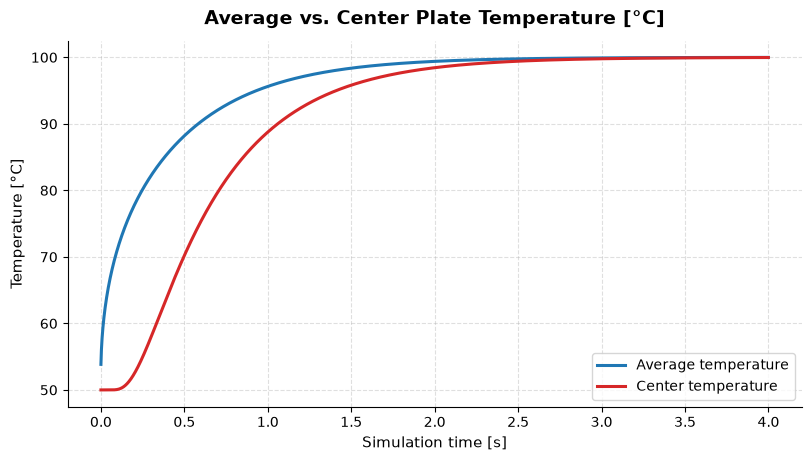

In [20]:

# Figure 2: Average vs. center temperature over time

time_array = np.arange(time_nodes) * time_step

fig, ax = plt.subplots(
    figsize=(8, 4.5),
    layout="constrained",
)

# Plot temperatures
ax.plot(
    time_array,
    average_temperature_collection,
    label="Average temperature",
    color="tab:blue",
    linewidth=2.2,
)

ax.plot(
    time_array,
    center_temperature_collection,
    label="Center temperature",
    color="tab:red",
    linewidth=2.2,
)

# Labels and title
ax.set_title(
    "Average vs. Center Plate Temperature [°C]",
    fontsize=14,
    fontweight="bold",
    pad=12,
)

ax.set_xlabel("Simulation time [s]", fontsize=11)
ax.set_ylabel("Temperature [°C]", fontsize=11)

# Grid and legend
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend(frameon=True, loc="best")

# Clean up the axes
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="both", labelsize=10)

# Export
fig.savefig(
    FIGURES_DIR / "fig_temperature_evolution.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)
